In [5]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import os

In [2]:
ds = xr.open_dataset("~/data/climatebench/outputs_historical.nc")
ds


<xarray.Dataset> Size: 137MB
Dimensions:                    (member: 3, time: 165, lat: 96, lon: 144)
Coordinates:
  * member                     (member) int64 24B 1 2 3
  * time                       (time) int64 1kB 1850 1851 1852 ... 2013 2014
  * lat                        (lat) float64 768B -90.0 -88.11 ... 88.11 90.0
  * lon                        (lon) float64 1kB 0.0 2.5 5.0 ... 355.0 357.5
    quantile                   float64 8B ...
Data variables:
    diurnal_temperature_range  (member, time, lat, lon) float32 27MB ...
    tas                        (member, time, lat, lon) float32 27MB ...
    pr                         (member, time, lat, lon) float32 27MB ...
    pr90                       (member, time, lat, lon) float64 55MB ...

In [3]:
for v in ds.data_vars:
    print(v, ds[v].attrs, float(ds[v].mean()))

for exp in ["historical", "ssp126", "ssp370", "ssp585", "hist-GHG", "hist-aer", "ssp245"]:
    d = xr.open_dataset(f"~/data/climatebench/outputs_{exp}.nc")
    print(exp, dict(d.sizes))


diurnal_temperature_range {} -0.04053613916039467
tas {} 0.25270137190818787
pr {} 3.482879318283949e-09
pr90 {} 5.120073120341493e-08
historical {'member': 3, 'time': 165, 'lat': 96, 'lon': 144}
ssp126 {'member': 1, 'time': 86, 'lat': 96, 'lon': 144}
ssp370 {'member': 3, 'time': 86, 'lat': 96, 'lon': 144}
ssp585 {'member': 1, 'time': 86, 'lat': 96, 'lon': 144}
hist-GHG {'member': 3, 'time': 165, 'lat': 96, 'lon': 144}
hist-aer {'member': 3, 'time': 165, 'lat': 96, 'lon': 144}
ssp245 {'member': 3, 'time': 86, 'lat': 96, 'lon': 144}


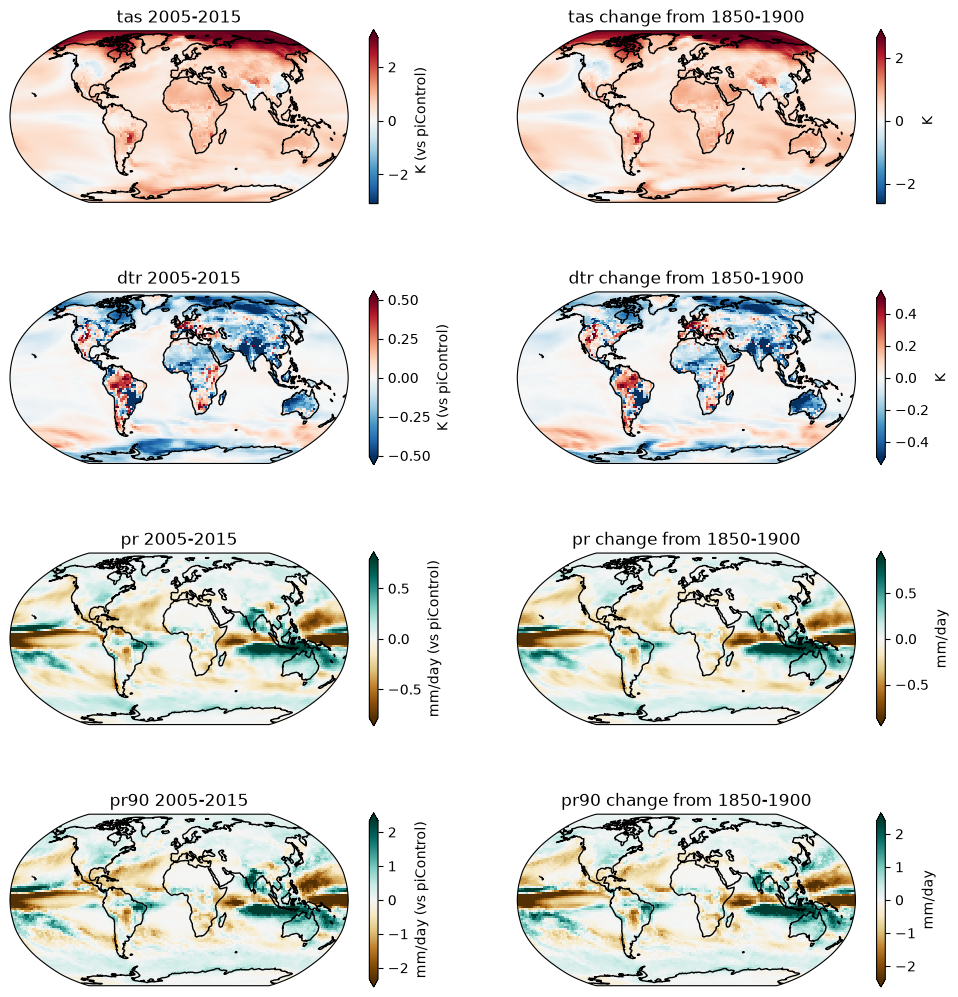

In [6]:
DATA = "~/data/climatebench"

# targets are stored as anomalies vs the piControl mean; average the 3 members
hist = xr.open_dataset(f"{DATA}/outputs_historical.nc").mean("member")
ssp = xr.open_dataset(f"{DATA}/outputs_ssp245.nc").mean("member")

# historical ends in 2014; take 2015 from ssp245 to complete the 2005-2015 window
recent = xr.concat([hist.sel(time=slice(2005, 2014)), ssp.sel(time=[2015])],
                   dim="time").mean("time")
early = hist.sel(time=slice(1850, 1900)).mean("time")
diff = recent - early

# the files have no units attrs: temperatures are K, precip is kg m-2 s-1 (-> mm/day)
targets = {
    "tas": ("tas", "K", 1, "RdBu_r"),
    "diurnal_temperature_range": ("dtr", "K", 1, "RdBu_r"),
    "pr": ("pr", "mm/day", 86400, "BrBG"),
    "pr90": ("pr90", "mm/day", 86400, "BrBG"),
}

fig, axes = plt.subplots(4, 2, figsize=(12, 13),
                         subplot_kw={"projection": ccrs.Robinson()})

for row, (var, (name, unit, scale, cmap)) in enumerate(targets.items()):
    panels = [
        (recent[var] * scale, f"{name} 2005-2015", f"{unit} (vs piControl)"),
        (diff[var] * scale, f"{name} change from 1850-1900", unit),
    ]
    for ax, (da, title, label) in zip(axes[row], panels):
        # symmetric color limits around 0, clipped at the 98th percentile
        vmax = float(np.nanpercentile(np.abs(da), 98))
        da.plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap,
                vmin=-vmax, vmax=vmax,
                cbar_kwargs={"label": label, "shrink": 0.8})
        ax.coastlines()
        ax.set_title(title)

out = os.path.expanduser("~/DSC180-D06-JCM-Project/figures")
os.makedirs(out, exist_ok=True)
fig.savefig(f"{out}/task1_maps.png", dpi=150, bbox_inches="tight")


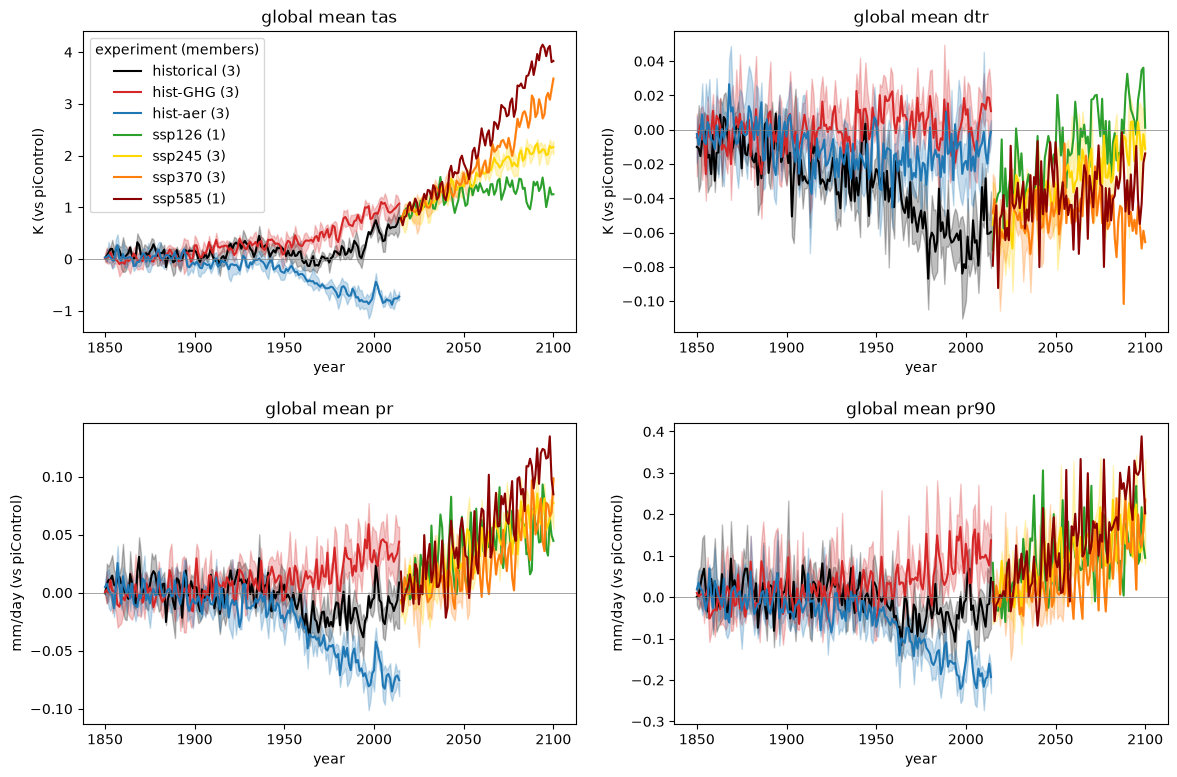

In [7]:
experiments = {
    "historical": "black",
    "hist-GHG": "tab:red",
    "hist-aer": "tab:blue",
    "ssp126": "tab:green",
    "ssp245": "gold",
    "ssp370": "tab:orange",
    "ssp585": "darkred",
}

# global mean per member, weighting each grid cell by cos(lat) (cell area shrinks toward the poles)
gmean = {}
for exp in experiments:
    ds = xr.open_dataset(f"{DATA}/outputs_{exp}.nc")
    weights = np.cos(np.deg2rad(ds.lat))
    gmean[exp] = ds.weighted(weights).mean(["lat", "lon"])

targets = {
    "tas": ("tas", "K", 1),
    "diurnal_temperature_range": ("dtr", "K", 1),
    "pr": ("pr", "mm/day", 86400),
    "pr90": ("pr90", "mm/day", 86400),
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9), gridspec_kw={"hspace": 0.3})

for ax, (var, (name, unit, scale)) in zip(axes.flat, targets.items()):
    for exp, color in experiments.items():
        da = gmean[exp][var] * scale
        # line = ensemble mean, shading = min to max across members
        ax.plot(da.time, da.mean("member"), color=color, label=f"{exp} ({da.sizes['member']})")
        if da.sizes["member"] > 1:
            ax.fill_between(da.time, da.min("member"), da.max("member"), color=color, alpha=0.25)
    ax.axhline(0, color="gray", lw=0.5)
    ax.set_title(f"global mean {name}")
    ax.set_xlabel("year")
    ax.set_ylabel(f"{unit} (vs piControl)")

axes[0, 0].legend(title="experiment (members)")

out = os.path.expanduser("~/DSC180-D06-JCM-Project/figures")
os.makedirs(out, exist_ok=True)
fig.savefig(f"{out}/task2_timeseries.png", dpi=150, bbox_inches="tight")


historical 0.30 K per 1000 GtCO2
ssp126     0.36 K per 1000 GtCO2
ssp245     0.45 K per 1000 GtCO2
ssp370     0.46 K per 1000 GtCO2
ssp585     0.43 K per 1000 GtCO2


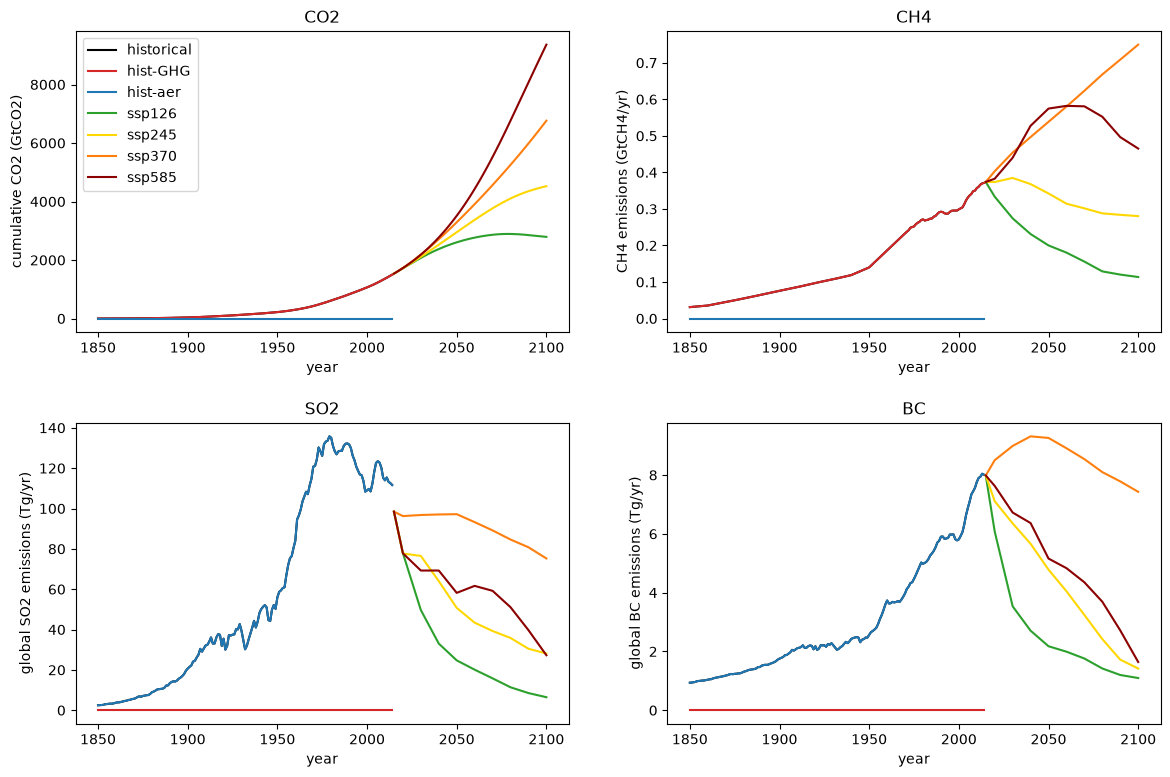

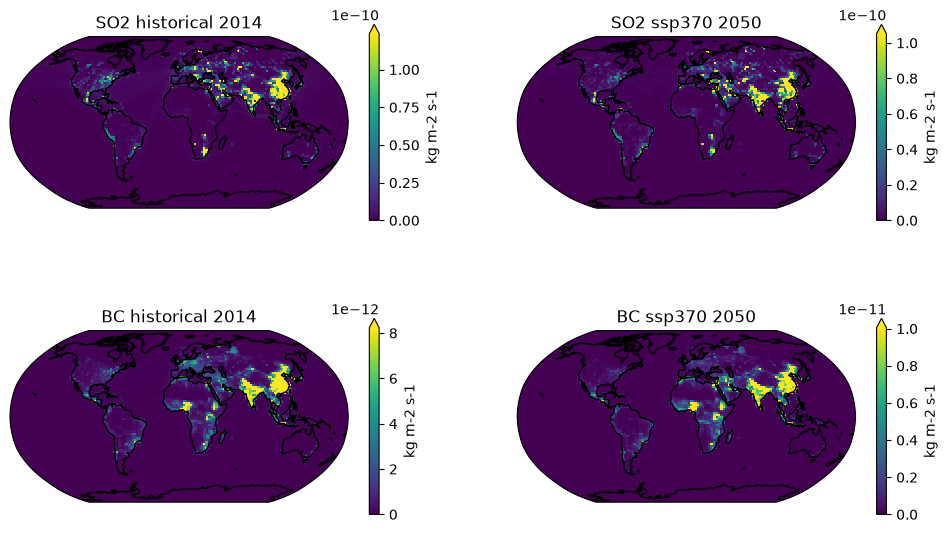

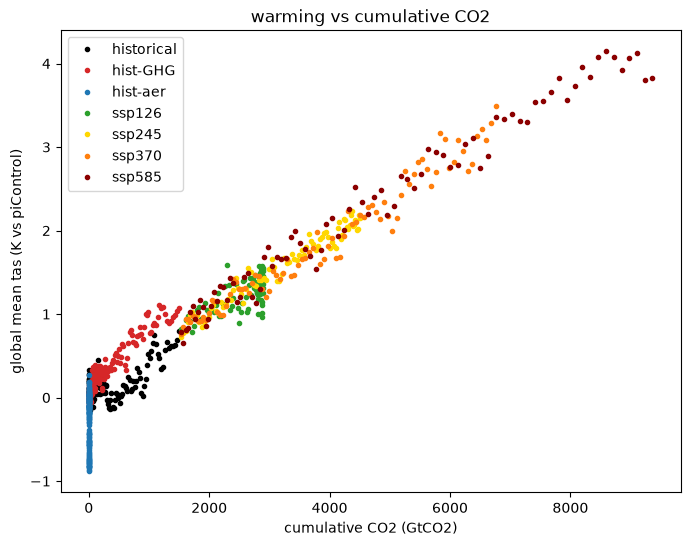

In [8]:
# inputs use latitude/longitude, not lat/lon like the outputs
inputs = {exp: xr.open_dataset(f"{DATA}/inputs_{exp}.nc") for exp in experiments}

EARTH_AREA = 5.1e14             # m^2
SEC_PER_YEAR = 365.25 * 86400


def global_total(da):
    # SO2/BC are fluxes in kg m-2 s-1: area-weighted mean x Earth's area x seconds -> Tg/yr
    w = np.cos(np.deg2rad(da.latitude))
    return da.weighted(w).mean(["latitude", "longitude"]) * EARTH_AREA * SEC_PER_YEAR / 1e9


# 1) all four inputs over time, one line per experiment
fig, axes = plt.subplots(2, 2, figsize=(14, 9), gridspec_kw={"hspace": 0.3})
panels = [
    ("CO2", "cumulative CO2 (GtCO2)", lambda d: d["CO2"]),
    ("CH4", "CH4 emissions (GtCH4/yr)", lambda d: d["CH4"]),
    ("SO2", "global SO2 emissions (Tg/yr)", lambda d: global_total(d["SO2"])),
    ("BC", "global BC emissions (Tg/yr)", lambda d: global_total(d["BC"])),
]
for ax, (name, label, get) in zip(axes.flat, panels):
    for exp, color in experiments.items():
        series = get(inputs[exp])
        ax.plot(series.time, series, color=color, label=exp)
    ax.set_title(name)
    ax.set_xlabel("year")
    ax.set_ylabel(label)
axes[0, 0].legend()
fig.savefig(f"{out}/task3_inputs.png", dpi=150, bbox_inches="tight")

# 2) SO2 and BC are maps: show where emissions are, 2014 vs ssp370 in 2050
fig, axes = plt.subplots(2, 2, figsize=(12, 7),
                         subplot_kw={"projection": ccrs.Robinson()})
for row, name in enumerate(["SO2", "BC"]):
    for ax, (exp, year) in zip(axes[row], [("historical", 2014), ("ssp370", 2050)]):
        da = inputs[exp][name].sel(time=year)
        da.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="viridis",
                vmin=0, vmax=float(np.nanpercentile(da, 99)),
                cbar_kwargs={"label": "kg m-2 s-1", "shrink": 0.8})
        ax.coastlines()
        ax.set_title(f"{name} {exp} {year}")
fig.savefig(f"{out}/task3_aerosol_maps.png", dpi=150, bbox_inches="tight")

# 3) global mean tas (from task 2) against cumulative CO2
fig, ax = plt.subplots(figsize=(8, 6))
for exp, color in experiments.items():
    ax.plot(inputs[exp]["CO2"], gmean[exp]["tas"].mean("member"),
            ".", color=color, label=exp)
ax.set_xlabel("cumulative CO2 (GtCO2)")
ax.set_ylabel("global mean tas (K vs piControl)")
ax.set_title("warming vs cumulative CO2")
ax.legend()
fig.savefig(f"{out}/task3_tas_vs_co2.png", dpi=150, bbox_inches="tight")

# slope of warming per 1000 GtCO2 in the scenarios that have CO2 and aerosols
for exp in ["historical", "ssp126", "ssp245", "ssp370", "ssp585"]:
    slope = np.polyfit(inputs[exp]["CO2"], gmean[exp]["tas"].mean("member"), 1)[0]
    print(f"{exp:10s} {slope * 1000:.2f} K per 1000 GtCO2")


**Which inputs are global scalars, and which are maps?**

CO2 and CH4 are global scalars, with one value per year (dimension `time`). CO2 is cumulative emissions and CH4 is annual emissions. 
SO2 and BC are maps (`time, latitude, longitude`), stored as emission fluxes in kg m-2 s-1. 

**How does cumulative CO2 relate to the temperature time series in (2)?**

Global-mean temperature rises roughly linearly with cumulative CO2. When temperature is plotted against cumulative CO2, all four SSPs fall close to one straight line.